In [91]:
import warnings, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60, "display.width", 200, "display.max_rows", 100)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110


FULL_YEARS   = list(range(2020, 2026))   # 2026 is a partial year (data ends late Oct 2026)
PARTIAL_YEAR = 2026

# What counts as retail (CMPD's own PLACE_TYPE_DESCRIPTION == 'Retail', minus non-store venues)
RETAIL_PLACE_TYPES = ["Retail"]
NON_STORE_DETAILS  = ["Amusement Park", "Gambling Facility/Casino/Race Track", "Mobile Home Dealership"]
# Optional sensitivity check: pull in food/hospitality that CMPD files under 'Commercial Place'
EXTRA_DETAILS = []        # e.g. ["Restaurant/Diner/Coffee Shop"]

# NIBRS codes that are not crimes at a store (administrative / medical / recovery reports)
NON_CRIME_NIBRS = {"899": "Other Unlisted Non-Criminal", "800": "Missing Person", "801": "Suicide",
                   "802": "Sudden/Natural Death", "803": "Overdose", "806": "Gas Leak",
                   "807": "Public Accident", "809": "Vehicle Recovery", "810": "Fire (Accidental)"}

# Definition of "solved":  'cleared_any' = arrest OR exceptional clearance;  'cleared_arrest' = arrest only
SOLVED_DEF = "cleared_any"

Load the file

In [92]:
raw = pd.read_csv("data\CMPD_Incidents (1).csv", low_memory=False)
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
display(raw.head(3).T)

Rows: 682,391   Columns: 29


,0,1,2
X,1460051.999933,1450633.000071,1441462.00004
Y,531863.000115,531681.000151,540017.999881
YEAR,2017,2020,2025
INCIDENT_REPORT_ID,20170826-2346-00,20200112-1121-00,20250917-1605-00
LOCATION,3100 SAM DRENAN RD,1900 EAST BV,1100 SPRUCE ST
CITY,CHARLOTTE,CHARLOTTE,CHARLOTTE
STATE,NC,NC,NC
ZIP,28205,28203,28203
X_COORD_PUBLIC,1460052,1450633,1441462
Y_COORD_PUBLIC,531863,531681,540018


In [93]:
audit = pd.DataFrame({"dtype": raw.dtypes.astype(str),
                      "pct_missing": (raw.isna().mean()*100).round(1),
                      "n_unique": raw.nunique()})
display(audit)

,dtype,pct_missing,n_unique
X,float64,0.0,21384
Y,float64,0.0,21795
YEAR,int64,0.0,10
INCIDENT_REPORT_ID,object,0.0,556219
LOCATION,object,0.0,36873
CITY,object,0.0,71
STATE,object,0.0,4
ZIP,object,34.8,583
X_COORD_PUBLIC,int64,0.0,21384
Y_COORD_PUBLIC,int64,0.0,21795


**Things to note from the audit**
- Every row is one offense-level incident record; `INCIDENT_REPORT_ID` carries a `-00/-01/...` suffix for multiple incidents on one report.
- Dates are **date-only** stored as midnight local time in UTC (04:00/05:00). There is **no time of day**, so "when" analysis is limited to day-of-week, month, and year.
- `ZIP` is ~35% missing, so we use `CMPD_PATROL_DIVISION`, `NPA` (Neighborhood Profile Area), and coordinates for geography instead.
- `DATE_INCIDENT_BEGAN` contains obvious typos (years like 0202, 1979–1981); these are neutralised by the 0–365 day lag filter in Section 2.

Cleaning

In [94]:
df = raw.copy()

# 2a. Exact duplicates (rows identical except for the system keys OBJECTID / GlobalID)
key_cols = [c for c in df.columns if c not in ("OBJECTID", "GlobalID")]
n_before = len(df)
df = df.drop_duplicates(subset=key_cols).reset_index(drop=True)
print(f"Exact duplicates removed: {n_before - len(df):,}  ({(n_before-len(df))/n_before:.1%})  ->  {len(df):,} rows")

Exact duplicates removed: 126,151  (18.5%)  ->  556,240 rows


In [95]:
# 2b. Dates: parse UTC, convert to Charlotte local time, keep the calendar date
def parse_local_date(s):
    return (pd.to_datetime(s, utc=True, errors="coerce")
              .dt.tz_convert("America/New_York").dt.tz_localize(None).dt.normalize())

df["date_reported"] = parse_local_date(df["DATE_REPORTED"])
df["date_began"]    = parse_local_date(df["DATE_INCIDENT_BEGAN"])
df["date_end"]      = parse_local_date(df["DATE_INCIDENT_END"])
df["date_cleared"]  = parse_local_date(df["CLEARANCE_DATE"])

# Report lag = days between incident start and report. Keep only plausible values (0-365 days).
lag = (df["date_reported"] - df["date_began"]).dt.days
print(f"Incident-start dates before 2000 (typos like year 0202, or very old reports): {(df['date_began'].dt.year < 2000).sum():,}")
print(f"Negative lag (began after reported):  {(lag < 0).sum():,}")
print(f"Lag > 365 days:                       {(lag > 365).sum():,}")
df["report_lag_days"] = lag.where(lag.between(0, 365))

# Days to clearance (only where a valid clearance date exists)
dtc = (df["date_cleared"] - df["date_reported"]).dt.days
df["days_to_clear"] = dtc.where(dtc.between(0, 3650))

# Use the incident-start date for seasonality when valid, otherwise the reported date
df["date_event"] = df["date_began"].where(df["report_lag_days"].notna(), df["date_reported"])
df["year_reported"] = df["date_reported"].dt.year
assert (df["year_reported"] == df["YEAR"]).mean() > 0.99, "YEAR column should match DATE_REPORTED year"

Incident-start dates before 2000 (typos like year 0202, or very old reports): 61
Negative lag (began after reported):  0
Lag > 365 days:                       5,494


In [96]:
# 2c. Text normalisation
df["loc_key"] = (df["LOCATION"].fillna("").str.upper().str.replace(r"\s+", " ", regex=True).str.strip())
df["division"] = df["CMPD_PATROL_DIVISION"].fillna("Unknown")

# City has many typos (CHARLOTE, CHAROLETTE ...) - collapse obvious ones, we do not rely on it for geography
city = df["CITY"].fillna("").str.upper()
df["city_clean"] = np.where(city.str.startswith(("CHAR", "CHRA", "CAHR", "OCHAR")), "CHARLOTTE", city.str.title())
print(df["city_clean"].value_counts().head(8))

# 2d. Clearance outcome flags
df["cleared_arrest"] = df["CLEARANCE_STATUS"].isin(["Cleared by Arrest", "Cleared by Arrest by Another Agency"])
df["cleared_any"]    = ~df["CLEARANCE_STATUS"].isin(["Open", "Unfounded"])
df["solved"]         = df[SOLVED_DEF]

city_clean
CHARLOTTE       555187
Mecklenburg        398
Matthews           203
Pineville          191
Huntersville       123
Mint Hill           87
Cornelius           10
Davidson             6
Name: count, dtype: int64




Three decisions, applied in order and logged in a funnel table:

1. **Place:** CMPD's `PLACE_TYPE_DESCRIPTION == "Retail"` (gas stations, convenience, grocery, department, drug, malls, auto parts/dealerships, liquor, pawn, jewelry...). We drop venues that are not stores (amusement parks, casinos, mobile-home dealerships). Restaurants, hotels, bars and banks are filed under "Commercial Place" and are excluded by default (toggle with `EXTRA_DETAILS`).
2. **Offense:** drop non-crime administrative records (non-criminal reports, overdoses, deaths, missing persons, vehicle recoveries, accidents).
3. **Validity:** drop `Unfounded` cases (no crime occurred) and records with no patrol division.

In [97]:
funnel = []
def log(step, d): funnel.append({"step": step, "rows": len(d)})

log("0. All incidents (deduplicated)", df)
m_place = df["PLACE_TYPE_DESCRIPTION"].isin(RETAIL_PLACE_TYPES) | df["PLACE_DETAIL_DESCRIPTION"].isin(EXTRA_DETAILS)
r = df[m_place]; log("1. Place type = Retail", r)
r = r[~r["PLACE_DETAIL_DESCRIPTION"].isin(NON_STORE_DETAILS)]; log("2. Drop non-store venues", r)
r = r[~r["HIGHEST_NIBRS_CODE"].astype(str).isin(NON_CRIME_NIBRS)]; log("3. Drop non-crime NIBRS codes", r)
r = r[r["CLEARANCE_STATUS"] != "Unfounded"]; log("4. Drop unfounded cases", r)
r = r[r["division"] != "Unknown"]; log("5. Drop records with no patrol division", r)

funnel = pd.DataFrame(funnel)
funnel["dropped"] = funnel["rows"].diff().fillna(0).astype(int)
funnel["pct_of_all"] = (funnel["rows"] / funnel["rows"].iloc[0] * 100).round(1)
display(funnel)
retail = r.copy()
print(f"\nRetail crime analysis set: {len(retail):,} incidents, {retail['loc_key'].nunique():,} distinct address blocks")

,step,rows,dropped,pct_of_all
0,0. All incidents (deduplicated),556240,0,100.0
1,1. Place type = Retail,84139,-472101,15.1
2,2. Drop non-store venues,83530,-609,15.0
3,3. Drop non-crime NIBRS codes,77520,-6010,13.9
4,4. Drop unfounded cases,76017,-1503,13.7
5,5. Drop records with no patrol division,75982,-35,13.7



Retail crime analysis set: 75,982 incidents, 2,339 distinct address blocks


Store types and crime groups
`PLACE_DETAIL_DESCRIPTION` is grouped into analysis-friendly **store types**, and the ~60 NIBRS offenses into a handful of **crime groups**.

In [98]:
STORE_MAP = {
    "Department Store": "Department / big-box",
    "Grocery Store/Supermarket": "Grocery",
    "Convenience Store": "Convenience",
    "Gas Station": "Gas station",
    "Drug Store": "Drug store",
    "Shopping Mall": "Shopping mall",
    "Auto Parts/Service Center": "Auto parts / dealership",
    "Vehicle Dealership": "Auto parts / dealership",
    "ABC/Liquor Store": "Specialty (liquor/pawn/jewelry)",
    "Pawn Shop": "Specialty (liquor/pawn/jewelry)",
    "Jewelry Store": "Specialty (liquor/pawn/jewelry)",
    "Video Store": "Specialty (liquor/pawn/jewelry)",
    "Other - Retail": "Other retail",
}
CRIME_MAP = {
    "Shoplifting": "Shoplifting",
    "All Other Thefts": "Other theft", "Theft From Building": "Other theft", "Pocket-Picking": "Other theft",
    "Purse-Snatching": "Other theft", "Theft From Coin-Operated Machine Or Device": "Other theft",
    "Theft From Motor Vehicle": "Vehicle crime", "Motor Vehicle Theft": "Vehicle crime",
    "Theft of Motor Vehicle Parts from Vehicle": "Vehicle crime",
    "Burglary/B&E": "Burglary",
    "Robbery": "Robbery",
    "Simple Assault": "Violent (assault/threat)", "Aggravated Assault": "Violent (assault/threat)",
    "Intimidation": "Violent (assault/threat)", "Murder": "Violent (assault/threat)",
    "Forcible Rape": "Violent (assault/threat)", "Forcible Fondling": "Violent (assault/threat)",
    "Kidnapping": "Violent (assault/threat)", "Forcible Sodomy": "Violent (assault/threat)",
    "Sexual Assault With Object": "Violent (assault/threat)", "Justifiable Homicide": "Violent (assault/threat)",
    "Credit Card/Teller Fraud": "Fraud / forgery", "False Pretenses/Swindle": "Fraud / forgery",
    "Counterfeiting/Forgery": "Fraud / forgery", "Embezzlement": "Fraud / forgery",
    "Identity Theft": "Fraud / forgery", "Impersonation": "Fraud / forgery", "Wire Fraud": "Fraud / forgery",
    "Worthless Check: Felony (over $2000)": "Fraud / forgery", "Hacking/Computer Invasion": "Fraud / forgery",
    "Damage/Vandalism Of Property": "Vandalism / trespass", "Trespass Of Real Property": "Vandalism / trespass",
    "Arson": "Vandalism / trespass",
}
retail["store_type"]  = retail["PLACE_DETAIL_DESCRIPTION"].map(STORE_MAP).fillna("Other retail")
retail["crime_group"] = retail["HIGHEST_NIBRS_DESCRIPTION"].map(CRIME_MAP).fillna("Other offenses")

# Coarse flags used later
retail["is_shoplifting"] = retail["crime_group"].eq("Shoplifting")
retail["is_violent"]     = retail["crime_group"].isin(["Violent (assault/threat)", "Robbery"])
retail["dow"]   = retail["date_event"].dt.day_name()
retail["month"] = retail["date_event"].dt.month

print("Unmapped place details:", sorted(set(retail["PLACE_DETAIL_DESCRIPTION"]) - set(STORE_MAP)))
display(retail["store_type"].value_counts().to_frame("incidents").assign(pct=lambda d: (d.incidents/d.incidents.sum()*100).round(1)))
display(retail["crime_group"].value_counts().to_frame("incidents").assign(pct=lambda d: (d.incidents/d.incidents.sum()*100).round(1)))
print("Largest raw offense types landing in 'Other offenses':")
display(retail.loc[retail.crime_group == "Other offenses", "HIGHEST_NIBRS_DESCRIPTION"].value_counts().head(8))

Unmapped place details: []


,incidents,pct
store_type,,
Department / big-box,14861,19.6
Other retail,14693,19.3
Gas station,13230,17.4
Convenience,11792,15.5
Grocery,8725,11.5
Auto parts / dealership,4990,6.6
Shopping mall,4217,5.5
Drug store,2826,3.7
Specialty (liquor/pawn/jewelry),648,0.9


,incidents,pct
crime_group,,
Shoplifting,31910,42.0
Other offenses,8862,11.7
Other theft,8814,11.6
Vehicle crime,6366,8.4
Fraud / forgery,5876,7.7
Violent (assault/threat),5808,7.6
Vandalism / trespass,3254,4.3
Burglary,2714,3.6
Robbery,2378,3.1


Largest raw offense types landing in 'Other offenses':


HIGHEST_NIBRS_DESCRIPTION
All Other Offenses             4233
Drug/Narcotic Violations       2678
Stolen Property Offenses        571
Drug Equipment Violations       506
Weapon Law Violations           365
Indecent Exposure               122
Affray                           93
Driving Under The Influence      70
Name: count, dtype: int64

In [99]:
# Data-quality checks on the analysis set
print("Missing values (%):")
display((retail[["loc_key","division","NPA","LATITUDE_PUBLIC","LONGITUDE_PUBLIC","date_reported","date_event","report_lag_days"]]
         .isna().mean()*100).round(2).to_frame("pct_missing").T)
print("Lat range:", retail.LATITUDE_PUBLIC.min(), retail.LATITUDE_PUBLIC.max(),
      "| Lon range:", retail.LONGITUDE_PUBLIC.min(), retail.LONGITUDE_PUBLIC.max())
print("Date range:", retail.date_reported.min().date(), "->", retail.date_reported.max().date())
print("Report IDs repeated within retail set:", retail.INCIDENT_REPORT_ID.duplicated().sum())

Missing values (%):


,loc_key,division,NPA,LATITUDE_PUBLIC,LONGITUDE_PUBLIC,date_reported,date_event,report_lag_days
pct_missing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.28


Lat range: 35.022078 35.44412 | Lon range: -81.039345 -80.613867
Date range: 2017-01-01 -> 2026-10-26
Report IDs repeated within retail set: 0


Some EDA

,incidents,shoplifting,solve_rate,arrest_rate,partial_year
year_reported,,,,,
2017,6998,2435,0.359,0.301,False
2018,8041,3307,0.344,0.284,False
2019,8622,3757,0.361,0.297,False
2020,8180,3502,0.329,0.269,False
2021,7196,2866,0.316,0.252,False
2022,7551,2789,0.301,0.222,False
2023,7676,3171,0.292,0.211,False
2024,7825,3481,0.259,0.184,False
2025,7898,3793,0.274,0.209,False


Shoplifting reports 2020 -> 2025: 3,502 -> 3,793 (+8%)
All-retail solve rate ('cleared_any') 2020 -> 2025: 32.9% -> 27.4%
Shoplifting 2020 -> 2025: +8%  (check whether this step-change is real or a reporting/NIBRS-coding artifact before trusting a 2020 baseline)


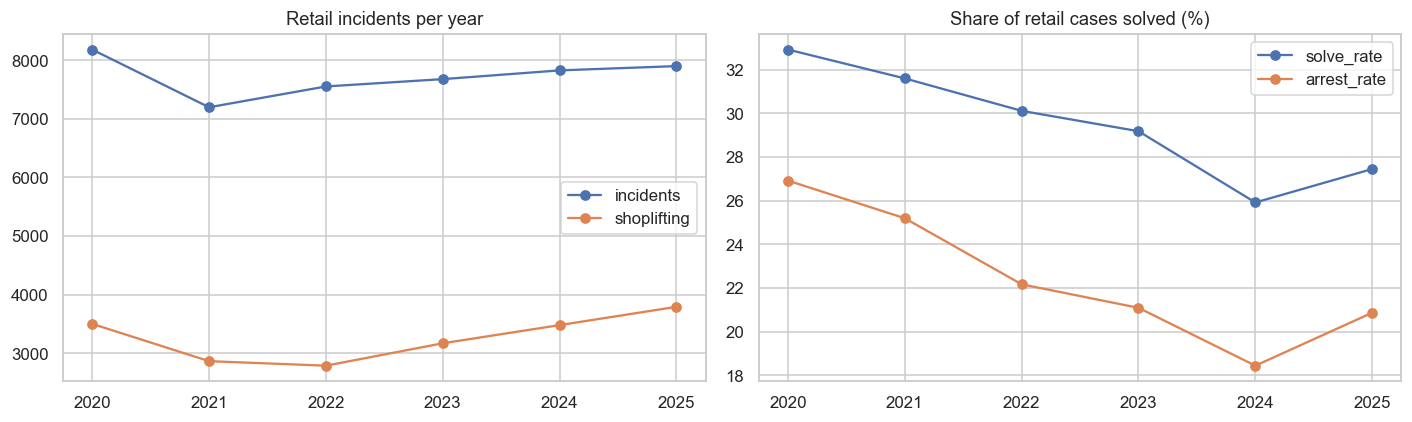

In [100]:
by_year = (retail.groupby("year_reported")
           .agg(incidents=("solved", "size"),
                shoplifting=("is_shoplifting", "sum"),
                solve_rate=("solved", "mean"),
                arrest_rate=("cleared_arrest", "mean")))
by_year["partial_year"] = by_year.index == PARTIAL_YEAR
display(by_year.round(3))

fy = by_year.loc[FULL_YEARS]
shop_chg = fy.loc[2025, "shoplifting"] / fy.loc[2020, "shoplifting"] - 1
solve_17, solve_25 = fy.loc[2020, "solve_rate"], fy.loc[2025, "solve_rate"]
print(f"Shoplifting reports 2020 -> 2025: {fy.loc[2020,'shoplifting']:,.0f} -> {fy.loc[2025,'shoplifting']:,.0f} ({shop_chg:+.0%})")
print(f"All-retail solve rate ('{SOLVED_DEF}') 2020 -> 2025: {solve_17:.1%} -> {solve_25:.1%}")
print(f"Shoplifting 2020 -> 2025: {fy.loc[2025,'shoplifting']/fy.loc[2020,'shoplifting']-1:+.0%}  "
      "(check whether this step-change is real or a reporting/NIBRS-coding artifact before trusting a 2020 baseline)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
fy[["incidents", "shoplifting"]].plot(ax=ax[0], marker="o")
ax[0].set_title("Retail incidents per year"); ax[0].set_xlabel("")
(fy[["solve_rate", "arrest_rate"]] * 100).plot(ax=ax[1], marker="o")
ax[1].set_title("Share of retail cases solved (%)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

Which stores face which crimes

crime_group,Burglary,Fraud / forgery,Other offenses,Other theft,Robbery,Shoplifting,Vandalism / trespass,Vehicle crime,Violent (assault/threat),TOTAL
store_type,,,,,,,,,,
Department / big-box,485,900,769,1564,381,9272,360,534,596,14861
Other retail,497,1479,782,1644,232,8267,420,811,561,14693
Gas station,343,653,3055,1546,697,2942,904,1199,1891,13230
Convenience,540,721,1683,1407,558,4323,599,657,1304,11792
Grocery,251,951,955,1436,258,3229,364,566,715,8725
Auto parts / dealership,367,454,883,450,46,275,269,1905,341,4990
Shopping mall,59,275,531,420,92,1755,244,587,254,4217
Drug store,98,333,100,268,85,1695,65,76,106,2826
Specialty (liquor/pawn/jewelry),74,110,104,79,29,152,29,31,40,648


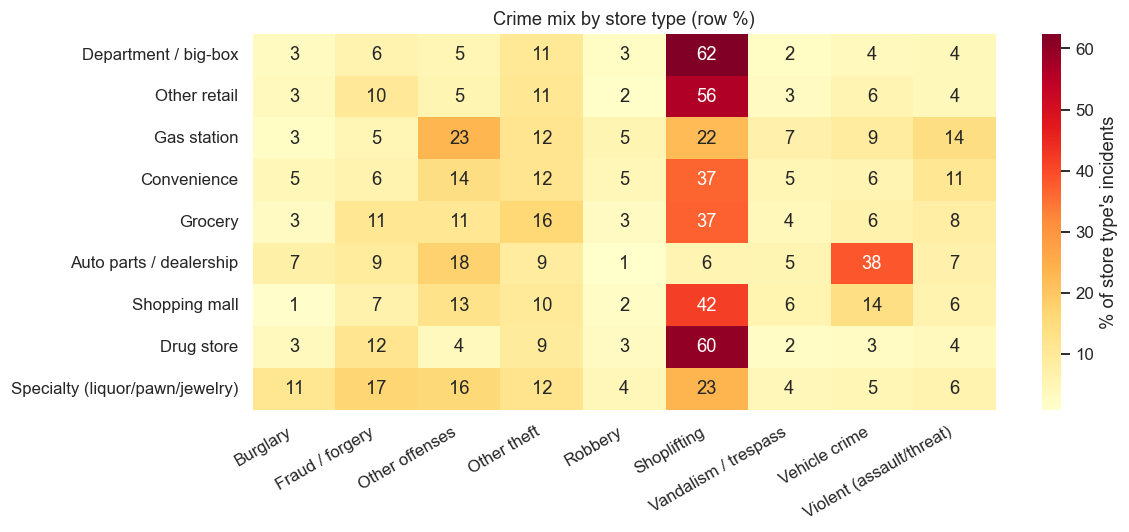

Lift vs. overall retail mix (>1 = over-represented):


crime_group,Burglary,Fraud / forgery,Other offenses,Other theft,Robbery,Shoplifting,Vandalism / trespass,Vehicle crime,Violent (assault/threat)
store_type,,,,,,,,,
Department / big-box,0.91,0.78,0.44,0.91,0.82,1.49,0.57,0.43,0.52
Other retail,0.95,1.30,0.46,0.96,0.50,1.34,0.67,0.66,0.50
Gas station,0.73,0.64,1.98,1.01,1.68,0.53,1.60,1.08,1.87
Convenience,1.28,0.79,1.22,1.03,1.51,0.87,1.19,0.67,1.45
Grocery,0.81,1.41,0.94,1.42,0.94,0.88,0.97,0.77,1.07
Auto parts / dealership,2.06,1.18,1.52,0.78,0.29,0.13,1.26,4.56,0.89
Shopping mall,0.39,0.84,1.08,0.86,0.70,0.99,1.35,1.66,0.79
Drug store,0.97,1.52,0.30,0.82,0.96,1.43,0.54,0.32,0.49
Specialty (liquor/pawn/jewelry),3.20,2.20,1.38,1.05,1.43,0.56,1.04,0.57,0.81


In [101]:
ct = pd.crosstab(retail["store_type"], retail["crime_group"])
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
order = ct.sum(axis=1).sort_values(ascending=False).index
display(ct.loc[order].assign(TOTAL=ct.sum(axis=1)))

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(ct_pct.loc[order], annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "% of store type's incidents"}, ax=ax)
ax.set_title("Crime mix by store type (row %)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

# Which store types over-index on each crime vs. the retail average (lift)
overall = retail["crime_group"].value_counts(normalize=True)
lift = ct_pct.div(overall * 100, axis=1)
print("Lift vs. overall retail mix (>1 = over-represented):")
display(lift.loc[order].round(2))

How much comes from the most-affected locations

A "location" here is the **address block** (`LOCATION`, e.g. `4400 SHARON RD`), which is the finest consistent identifier in the public data. Several stores in one shopping center share a block, so this is a *site/center* view rather than a single storefront.

1,911 distinct address blocks, 46,326 incidents (2020-2025)
Top   1% of locations (   19 blocks) -> 24.3% of incidents
Top   5% of locations (   96 blocks) -> 51.0% of incidents
Top  10% of locations (  191 blocks) -> 67.7% of incidents
Top  20% of locations (  382 blocks) -> 84.3% of incidents
Locations with only 1 incident: 36.5%


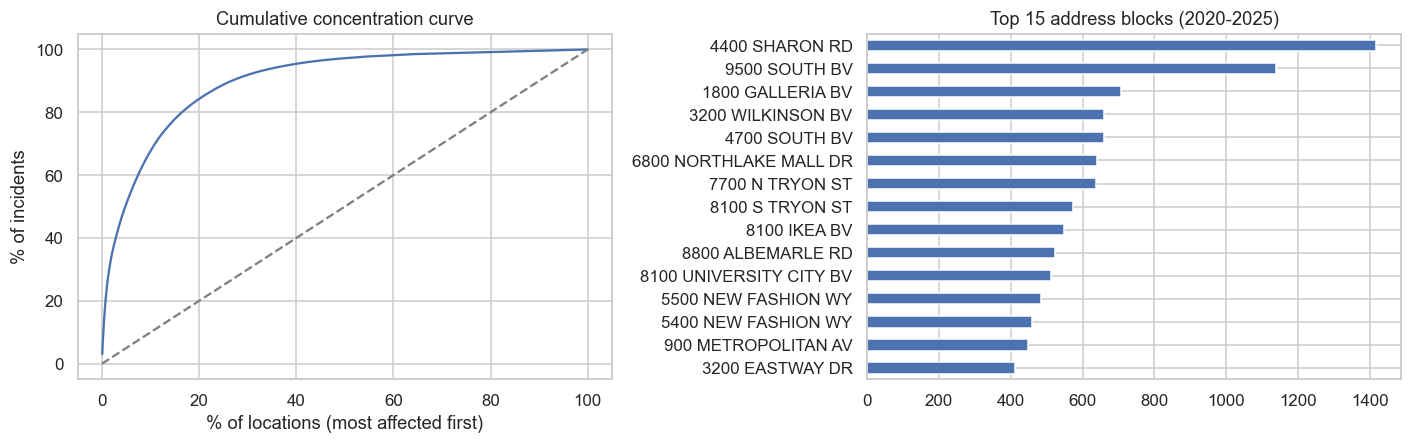

,incidents,shoplifting_pct,solve_rate,main_store_type,division
loc_key,,,,,
4400 SHARON RD,1417,59.9,37.1,Shopping mall,Providence
9500 SOUTH BV,1138,79.5,27.1,Department / big-box,Steele Creek
1800 GALLERIA BV,706,51.3,57.5,Department / big-box,Independence
3200 WILKINSON BV,660,39.1,36.5,Department / big-box,Freedom
4700 SOUTH BV,659,71.2,21.1,Department / big-box,Westover
6800 NORTHLAKE MALL DR,639,43.8,35.4,Shopping mall,North
7700 N TRYON ST,637,31.2,44.6,Department / big-box,University City
8100 S TRYON ST,572,50.0,21.5,Department / big-box,Steele Creek
8100 IKEA BV,548,84.7,17.5,Other retail,University City


In [102]:
loc_counts = (retail[retail.year_reported.isin(FULL_YEARS)].groupby("loc_key").size().sort_values(ascending=False))
n_loc, total = len(loc_counts), loc_counts.sum()
print(f"{n_loc:,} distinct address blocks, {total:,} incidents (2020-2025)")
for pct in (0.01, 0.05, 0.10, 0.20):
    k = max(1, int(round(n_loc * pct)))
    print(f"Top {pct:>4.0%} of locations ({k:>5,} blocks) -> {loc_counts.iloc[:k].sum()/total:5.1%} of incidents")
print(f"Locations with only 1 incident: {(loc_counts==1).mean():.1%}")

cum = loc_counts.cumsum() / total
x = np.arange(1, n_loc + 1) / n_loc
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(x * 100, cum.values * 100); ax[0].plot([0, 100], [0, 100], "--", color="grey")
ax[0].set_xlabel("% of locations (most affected first)"); ax[0].set_ylabel("% of incidents"); ax[0].set_title("Cumulative concentration curve")
loc_counts.head(15).iloc[::-1].plot.barh(ax=ax[1]); ax[1].set_title("Top 15 address blocks (2020-2025)"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

top = (retail[retail.year_reported.isin(FULL_YEARS)].groupby("loc_key")
       .agg(incidents=("solved", "size"), shoplifting_pct=("is_shoplifting", "mean"), solve_rate=("solved", "mean"),
            main_store_type=("store_type", lambda s: s.mode().iat[0]), division=("division", lambda s: s.mode().iat[0]))
       .sort_values("incidents", ascending=False).head(15))
top[["shoplifting_pct", "solve_rate"]] = (top[["shoplifting_pct", "solve_rate"]] * 100).round(1)
display(top)

When retail crime peaks

Only date (not hour) is available, so we look at day of week and month.

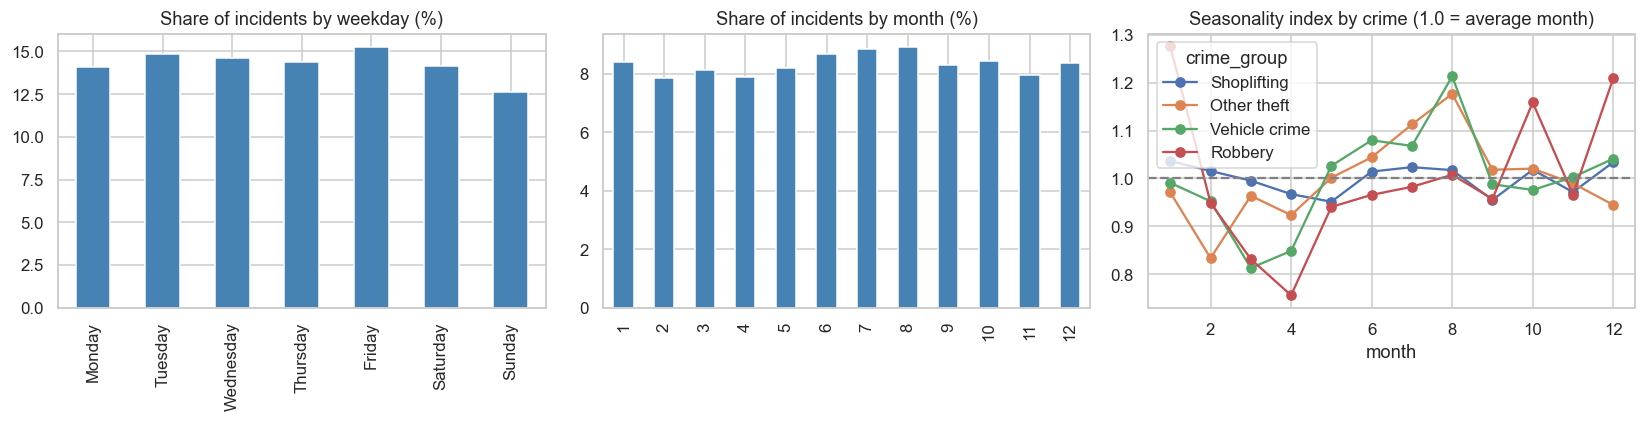

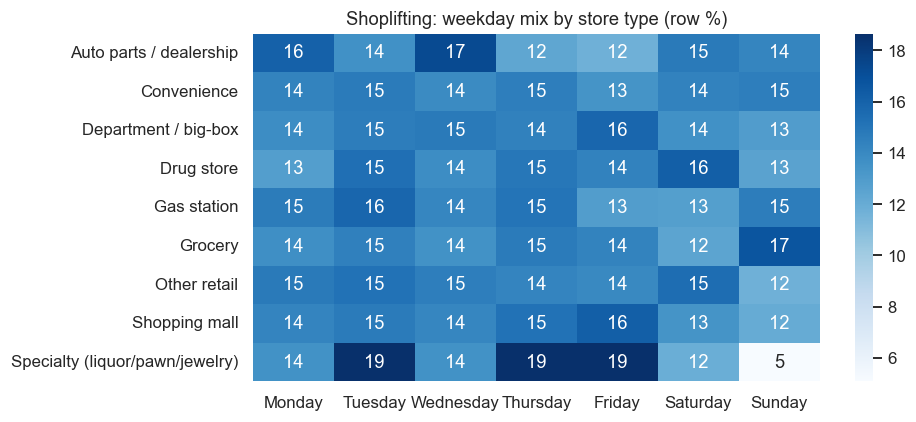

In [103]:
ev = retail[retail.year_reported.isin(FULL_YEARS)]
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

d = ev.groupby("dow").size().reindex(dow_order); (d / d.sum() * 100).plot.bar(ax=ax[0], color="steelblue")
ax[0].set_title("Share of incidents by weekday (%)"); ax[0].set_xlabel("")

mth = ev.groupby("month").size(); (mth / mth.sum() * 100).plot.bar(ax=ax[1], color="steelblue")
ax[1].set_title("Share of incidents by month (%)"); ax[1].set_xlabel("")

sm = ev.groupby(["month", "crime_group"]).size().unstack(fill_value=0)
sm = sm[["Shoplifting", "Other theft", "Vehicle crime", "Robbery"]]
(sm / sm.mean()).plot(ax=ax[2], marker="o"); ax[2].axhline(1, color="grey", ls="--")
ax[2].set_title("Seasonality index by crime (1.0 = average month)"); ax[2].set_xlabel("month")
plt.tight_layout(); plt.show()

# Weekday x store type, for shoplifting only
hm = pd.crosstab(ev[ev.is_shoplifting]["store_type"], ev[ev.is_shoplifting]["dow"])[dow_order]
plt.figure(figsize=(9, 4)); sns.heatmap(hm.div(hm.sum(axis=1), axis=0) * 100, annot=True, fmt=".0f", cmap="Blues")
plt.title("Shoplifting: weekday mix by store type (row %)"); plt.ylabel(""); plt.xlabel(""); plt.tight_layout(); plt.show()

,incidents,solve_rate,main_division
NPA,,,
331,2049,25.2,University City
358,1657,37.3,Providence
124,1586,31.0,Freedom
72,1501,29.6,North
3,1215,20.7,Central
142,1193,26.3,Steele Creek
476,1114,39.0,Central
45,1049,18.6,Steele Creek
393,1036,20.5,Westover


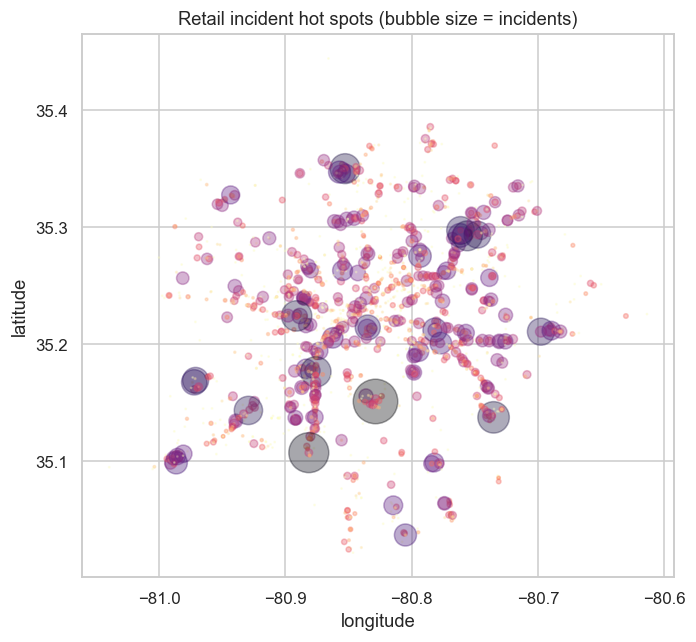

In [104]:
# Top neighborhoods (NPA) by volume - NPA IDs only; names would need the city's NPA lookup table
npa = (ev.groupby("NPA").agg(incidents=("solved", "size"), solve_rate=("solved", "mean"),
                             main_division=("division", lambda s: s.mode().iat[0]))
         .sort_values("incidents", ascending=False).head(15))
npa["solve_rate"] = (npa["solve_rate"] * 100).round(1)
display(npa)

# Rough geographic view of hot spots
hot = ev.groupby(["loc_key"]).agg(n=("solved", "size"), lat=("LATITUDE_PUBLIC", "median"), lon=("LONGITUDE_PUBLIC", "median"))
plt.figure(figsize=(6.5, 6))
plt.scatter(hot.lon, hot.lat, s=np.clip(hot.n, 1, None) * 0.6, alpha=0.35, c=np.log1p(hot.n), cmap="magma_r")
plt.title("Retail incident hot spots (bubble size = incidents)"); plt.xlabel("longitude"); plt.ylabel("latitude")
plt.tight_layout(); plt.show()

Modeling-ready preprocessing: location-year panel

**Prediction task:** *Using a location's incident history and store type, predict whether it lands in the top 10% of retail-incident counts next year.*

**Design (leakage-safe):**
- Unit = address block × year *t*. Features use **only data through year *t***; the label comes from year *t+1*.
- Universe at year *t* = blocks with at least one retail incident on or before *t*.
- Label = block's *t+1* count ≥ the 90th percentile of *t+1* counts across that universe (computed per year, so it adapts to volume).
- Use a **temporal split**, never a random one (see the split table below).
- Baseline to beat: rank blocks by last year's count.

In [105]:
YEARS = FULL_YEARS
base = retail[retail.year_reported.isin(YEARS)]

def yearly(series_fn):
    return series_fn.unstack(fill_value=0).reindex(columns=YEARS, fill_value=0)

cnt   = yearly(base.groupby(["loc_key", "year_reported"]).size())
shop  = yearly(base[base.is_shoplifting].groupby(["loc_key", "year_reported"]).size()).reindex(cnt.index, fill_value=0)
viol  = yearly(base[base.is_violent].groupby(["loc_key", "year_reported"]).size()).reindex(cnt.index, fill_value=0)
clr   = yearly(base[base.solved].groupby(["loc_key", "year_reported"]).size()).reindex(cnt.index, fill_value=0)
lagok = base.dropna(subset=["report_lag_days"])
lag_s = yearly(lagok.groupby(["loc_key", "year_reported"]).report_lag_days.sum()).reindex(cnt.index, fill_value=0)
lag_n = yearly(lagok.groupby(["loc_key", "year_reported"]).size()).reindex(cnt.index, fill_value=0)
print("Location x year matrix:", cnt.shape)

Location x year matrix: (1911, 6)


In [106]:
def mode_by_loc(frame, col):
    return frame.groupby("loc_key")[col].agg(lambda s: s.mode().iat[0])

rows = []
for t in YEARS[:-1]:                                   # t = 2020..2024, label year = t+1
    hist = [y for y in YEARS if y <= t]
    h_tot = cnt[hist].sum(axis=1)
    uni = h_tot[h_tot > 0].index                       # universe: seen at least once up to t
    past = base[base.year_reported <= t]
    p = pd.DataFrame(index=uni)
    p["as_of_year"] = t
    p["inc_t"]   = cnt.loc[uni, t]
    p["inc_t1"]  = cnt.loc[uni, t - 1] if t - 1 in YEARS else 0
    p["inc_t2"]  = cnt.loc[uni, t - 2] if t - 2 in YEARS else 0
    p["hist_total"]  = h_tot[uni]
    p["years_active"] = (cnt.loc[uni, hist] > 0).sum(axis=1)
    p["trend_1y"]    = p.inc_t - p.inc_t1
    p["shoplift_share"] = shop.loc[uni, hist].sum(axis=1) / p.hist_total
    p["violent_share"]  = viol.loc[uni, hist].sum(axis=1) / p.hist_total
    p["solve_rate_hist"] = clr.loc[uni, hist].sum(axis=1) / p.hist_total
    p["avg_report_lag"]  = lag_s.loc[uni, hist].sum(axis=1) / lag_n.loc[uni, hist].sum(axis=1).replace(0, np.nan)
    p["store_type"] = mode_by_loc(past, "store_type").reindex(uni)
    p["n_store_types"] = past.groupby("loc_key").store_type.nunique().reindex(uni)
    p["division"]   = mode_by_loc(past, "division").reindex(uni)
    p["npa"]        = mode_by_loc(past, "NPA").reindex(uni)
    p["lat"] = past.groupby("loc_key").LATITUDE_PUBLIC.median().reindex(uni)
    p["lon"] = past.groupby("loc_key").LONGITUDE_PUBLIC.median().reindex(uni)
    p["next_year_count"] = cnt.loc[uni, t + 1]
    thr = p.next_year_count.quantile(0.90)
    p["top10_threshold"] = thr
    p["top10_next_year"] = (p.next_year_count >= thr).astype(int)
    rows.append(p.reset_index())

panel = pd.concat(rows, ignore_index=True)
panel["avg_report_lag"] = panel["avg_report_lag"].fillna(panel["avg_report_lag"].median())
print("Panel shape:", panel.shape)
summ = (panel.groupby("as_of_year")
        .agg(locations=("loc_key", "size"), threshold=("top10_threshold", "first"),
             positives=("top10_next_year", "sum"), prevalence=("top10_next_year", "mean")))
display(summ.round(3))
print("NOTE: the threshold is an incident count (it falls over time as blocks accumulate), and ties at the cutoff push the positive rate slightly above 10%.")

Panel shape: (7147, 21)


,locations,threshold,positives,prevalence
as_of_year,,,,
2020,982,17.0,105,0.107
2021,1277,15.0,130,0.102
2022,1467,13.0,155,0.106
2023,1651,11.0,176,0.107
2024,1770,10.0,188,0.106


NOTE: the threshold is an incident count (it falls over time as blocks accumulate), and ties at the cutoff push the positive rate slightly above 10%.


In [107]:
# Temporal split plan (as_of_year -> predicts year+1)
split = pd.Series({y: ("train" if y <= 2022 else "validation" if y == 2023 else "test") for y in YEARS[:-1]}, name="split")
panel["split"] = panel.as_of_year.map(split)
display(panel.groupby("split").agg(as_of_years=("as_of_year", lambda s: f"{s.min()}-{s.max()}"),
                                   rows=("loc_key", "size"), positive_rate=("top10_next_year", "mean")).round(3))

,as_of_years,rows,positive_rate
split,,,
test,2024-2024,1770,0.106
train,2020-2022,3726,0.105
validation,2023-2023,1651,0.107


In [108]:
# Baseline: rank blocks by last year's count (ties broken by lifetime history) and flag the top-k, k = # of positives
def baseline_eval(g):
    k = int(g.top10_next_year.sum())
    ranked = g.sort_values(["inc_t", "hist_total"], ascending=False)
    hit = ranked.head(k).top10_next_year.sum()
    return pd.Series({"k": k, "baseline_precision@k": hit / k, "random_precision": g.top10_next_year.mean(),
                      "lift_vs_random": (hit / k) / g.top10_next_year.mean()})

bl = panel.groupby("as_of_year").apply(baseline_eval)
display(bl.round(3))
print("A trained model should beat 'baseline_precision@k' on the validation/test years (2023, 2024).")

# What does an incident-history signal look like? Persistence of hot spots
persist = panel.assign(had_incident_t=lambda d: d.inc_t > 0).groupby("had_incident_t").top10_next_year.mean() * 100
print("\n% landing in next-year top 10% by whether the block had an incident this year:")
display(persist.round(1))

,k,baseline_precision@k,random_precision,lift_vs_random
as_of_year,,,,
2020,105.0,0.724,0.107,6.769
2021,130.0,0.685,0.102,6.725
2022,155.0,0.735,0.106,6.961
2023,176.0,0.756,0.107,7.089
2024,188.0,0.713,0.106,6.711


A trained model should beat 'baseline_precision@k' on the validation/test years (2023, 2024).

% landing in next-year top 10% by whether the block had an incident this year:


had_incident_t
False     0.0
True     15.4
Name: top10_next_year, dtype: float64

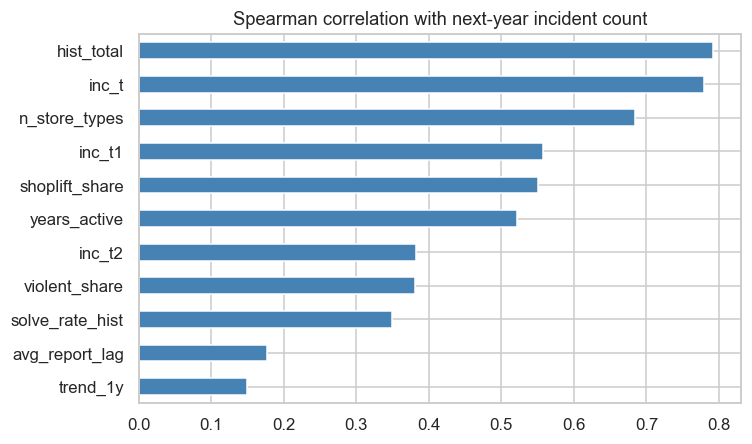

Series([], dtype: int64)


,blocks,top10_rate
store_type,,
Department / big-box,493,0.270
Gas station,998,0.213
Drug store,274,0.204
Grocery,635,0.189
Shopping mall,130,0.115
Convenience,982,0.089
Other retail,1567,0.071
Auto parts / dealership,1958,0.009
Specialty (liquor/pawn/jewelry),110,0.000


In [109]:
# Feature sanity check
feat_num = ["inc_t", "inc_t1", "inc_t2", "hist_total", "years_active", "trend_1y",
            "shoplift_share", "violent_share", "solve_rate_hist", "avg_report_lag", "n_store_types"]
corr = panel[feat_num + ["next_year_count"]].corr(method="spearman")["next_year_count"].drop("next_year_count").sort_values()
corr.plot.barh(figsize=(7, 4.2), color="steelblue"); plt.title("Spearman correlation with next-year incident count")
plt.tight_layout(); plt.show()

print(panel.isna().sum()[lambda s: s > 0])
display(panel.groupby("store_type").agg(blocks=("loc_key", "size"), top10_rate=("top10_next_year", "mean")).sort_values("top10_rate", ascending=False).round(3))

Export clean datasets

In [110]:
keep = ["INCIDENT_REPORT_ID", "loc_key", "LATITUDE_PUBLIC", "LONGITUDE_PUBLIC", "division", "NPA",
        "date_reported", "date_began", "date_event", "year_reported", "month", "dow", "report_lag_days",
        "PLACE_DETAIL_DESCRIPTION", "store_type", "LOCATION_TYPE_DESCRIPTION",
        "HIGHEST_NIBRS_CODE", "HIGHEST_NIBRS_DESCRIPTION", "crime_group", "is_shoplifting", "is_violent",
        "CLEARANCE_STATUS", "CLEARANCE_DETAIL_STATUS", "cleared_arrest", "cleared_any", "solved", "days_to_clear"]
retail[keep].to_csv(f"{OUT_DIR}/retail_incidents_clean.csv", index=False)
panel.to_csv(f"{OUT_DIR}/location_year_panel.csv", index=False)
funnel.to_csv(f"{OUT_DIR}/retail_filter_funnel.csv", index=False)
print("Saved:", os.listdir(OUT_DIR))

Saved: ['location_year_panel.csv', 'retail_filter_funnel.csv', 'retail_incidents_clean.csv']


### Next steps
1. Decide the final definition of **solved** (`cleared_any` vs. arrest-only) and of **retail** (try `EXTRA_DETAILS` as a sensitivity check).
2. Investigate the 2020→2018 shoplifting jump (possible reporting/coding change) before anchoring claims on 2020.
3. Fit models on `location_year_panel.csv` (logistic regression → gradient boosting) using the temporal split; compare precision@k against the baseline above.
4. Optionally enrich locations with NPA-level demographics (the supplementary violent-crime files could provide neighborhood *violent-crime context* by NPA if you want a neighborhood feature).